In [1]:
import polars as pl
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
counters = pl.read_csv("../../data/counters.csv", try_parse_dates=True)
counters.head()

,counter_site_id,counter_serial,channels_in,channels_out,channels_unknown,channels_all,site_temperature,site_rain_accumulation,datetime
i64,i64,str,f64,f64,str,i64,f64,f64,"datetime[μs, UTC]"
0,100003358,"""YTH24052174""",4.0,1.0,null,5,0.0,0.0,2020-12-31 23:00:00 UTC
1,100003358,"""YTH24052174""",2.0,0.0,null,2,0.0,0.0,2021-01-01 00:00:00 UTC
2,100003358,"""YTH24052174""",1.0,0.0,null,1,0.0,0.0,2021-01-01 01:00:00 UTC
3,100003358,"""YTH24052174""",2.0,0.0,null,2,0.0,0.0,2021-01-01 02:00:00 UTC
4,100003358,"""YTH24052174""",0.0,0.0,null,0,0.0,0.0,2021-01-01 03:00:00 UTC


In [33]:
min_max_dates = (
    counters.group_by(pl.col("counter_site_id"))
    .agg(
        pl.col("datetime").min().alias("start"),
        pl.col("datetime").max().alias("end")
    )
)
min_max_dates.describe()

statistic,counter_site_id,start,end
str,f64,str,str
"""count""",181.0,"""181""","""181"""
"""null_count""",0.0,"""0""","""0"""
"""mean""",2.2932e8,"""2022-08-31 23:52:42.430939+00:…","""2026-10-13 12:30:09.944751+00:…"
"""std""",9.5880e7,null,null
"""min""",1.00003358e8,"""2020-12-31 23:00:00+00:00""","""2023-03-13 22:00:00+00:00"""
"""25%""",1.00056853e8,"""2020-12-31 23:00:00+00:00""","""2026-10-31 22:00:00+00:00"""
"""50%""",3.00020056e8,"""2021-05-10 22:00:00+00:00""","""2026-10-31 22:00:00+00:00"""
"""75%""",3.00042289e8,"""2024-04-22 10:00:00+00:00""","""2026-10-31 22:00:00+00:00"""
"""max""",3.00069829e8,"""2026-06-10 12:00:00+00:00""","""2026-10-31 22:00:00+00:00"""


In [54]:
min_max_dates

counter_site_id,start,end
i64,"datetime[μs, UTC]","datetime[μs, UTC]"
100004165,2020-12-31 23:00:00 UTC,2026-10-31 22:00:00 UTC
300047874,2024-12-06 09:00:00 UTC,2026-10-31 22:00:00 UTC
300043250,2024-06-20 22:00:00 UTC,2026-10-31 22:00:00 UTC
300031088,2023-03-23 15:00:00 UTC,2026-10-31 22:00:00 UTC
300031079,2023-03-23 10:00:00 UTC,2026-10-31 22:00:00 UTC
…,…,…
100048812,2020-12-31 23:00:00 UTC,2026-10-31 22:00:00 UTC
100026408,2020-12-31 23:00:00 UTC,2026-10-31 22:00:00 UTC
300041398,2024-02-21 12:00:00 UTC,2026-10-31 22:00:00 UTC


<Axes: xlabel='start', ylabel='end'>

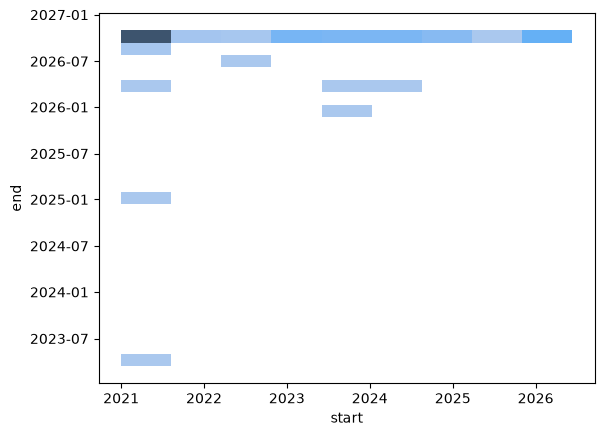

In [34]:
sns.histplot(data=min_max_dates.to_pandas(), x="start", y="end")

In [44]:
counters_with_enough_data = (
    min_max_dates.filter(
        pl.col("start") < pl.date(2021, 1, 1),
        pl.col("end") >= pl.date(2026, 10, 31)
    )
)

<Axes: ylabel='Probability'>

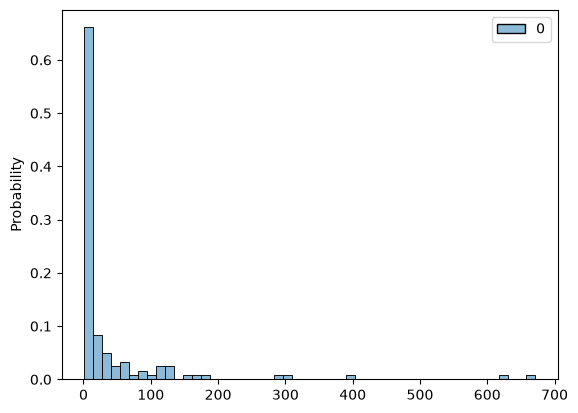

In [45]:
gaps_in_counters = (
    counters.group_by(
        pl.col("datetime").dt.date(),
        pl.col("counter_site_id"),
    )
    .agg(pl.col("channels_all").max())
    .filter(pl.col("channels_all") == 0)
    .group_by(pl.col("counter_site_id")).len()
)
sns.histplot(gaps_in_counters.select(pl.col("len")), stat="probability", bins=50)

In [102]:
gaps_in_counters.min()

counter_site_id,len
i64,u32
100003358,1


In [46]:
q = (
    gaps_in_counters
    .select(pl.col("len").quantile(0.95))
).item()
counters_with_gaps = (
    gaps_in_counters
    .filter(pl.col("len") > q)
)
counters_with_gaps

counter_site_id,len
i64,u32
100036542,401
100017862,181
100048814,671
100013034,621
300040059,287
100056853,307


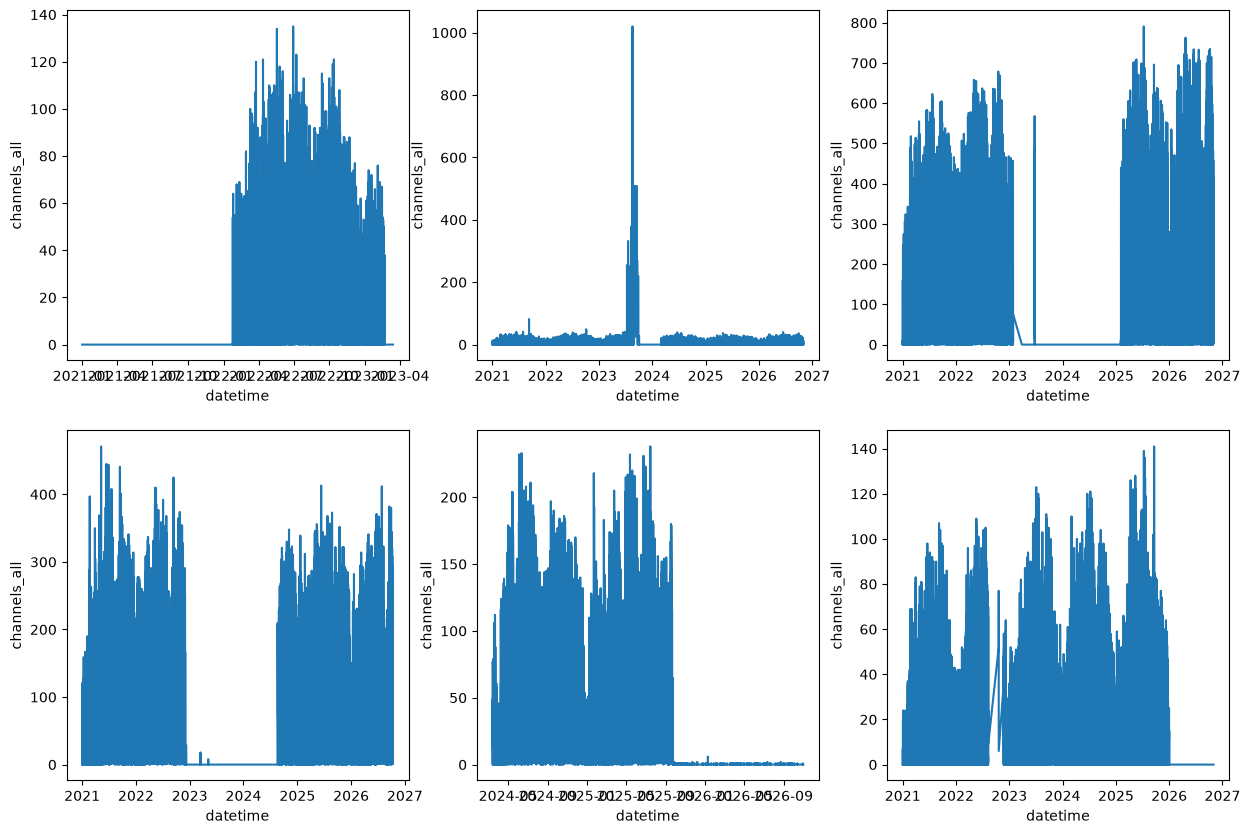

In [ ]:
N = counters_with_gaps.shape[0]
fig, axs = plt.subplots(2, 3, figsize=(5*3, 5*2))

for i in range(N):
    ax = axs.flatten()[i]
    site_id, l = counters_with_gaps.row(i)
    station_daily_peaks = (counters.filter(pl.col("counter_site_id") == site_id))
    sns.lineplot(data=station_daily_peaks, x="datetime", y="channels_all", ax=ax)

# Clearly some counters have significant gaps, and also outliers in the upper direction which are probably measuring errors

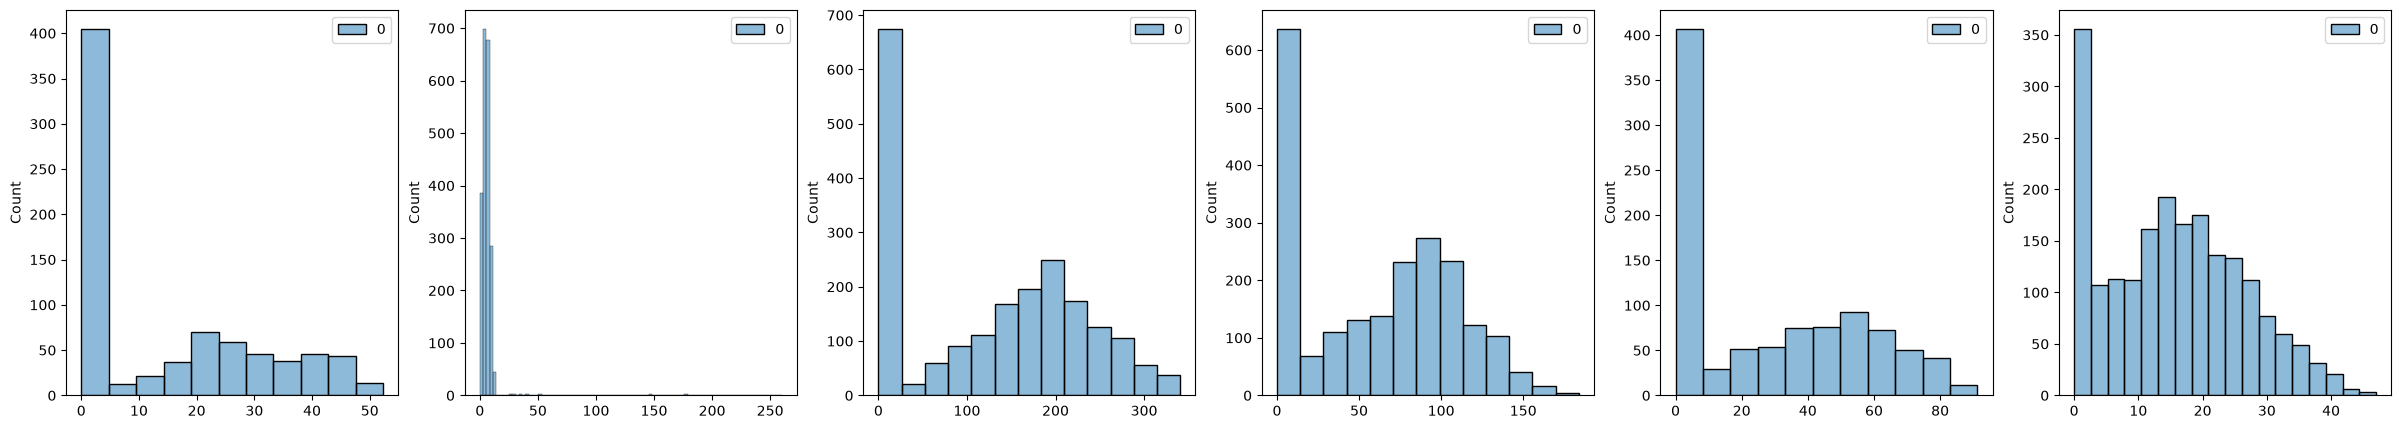

In [90]:
N = counters_with_gaps.shape[0]
fig, axs = plt.subplots(1, N, figsize=(5*N, 5))

for i in range(N):
    ax = axs[i]
    site_id, l = counters_with_gaps.row(i)
    station_daily_peaks = (
        counters
        .filter(pl.col("counter_site_id") == site_id)
        .group_by(by=pl.col("datetime").dt.date())
        .agg(pl.col("channels_all").mean())
        .select(pl.col("channels_all"))
    )
    sns.histplot(station_daily_peaks, ax=ax)

# The daily peaks seem to be normally distributed

In [92]:
gaps_in_counters.filter(pl.col("len") == 1)

counter_site_id,len
i64,u32
100035363,1
300015618,1
100063203,1
300018445,1
300020139,1
…,…
100056769,1
100059187,1
100063206,1


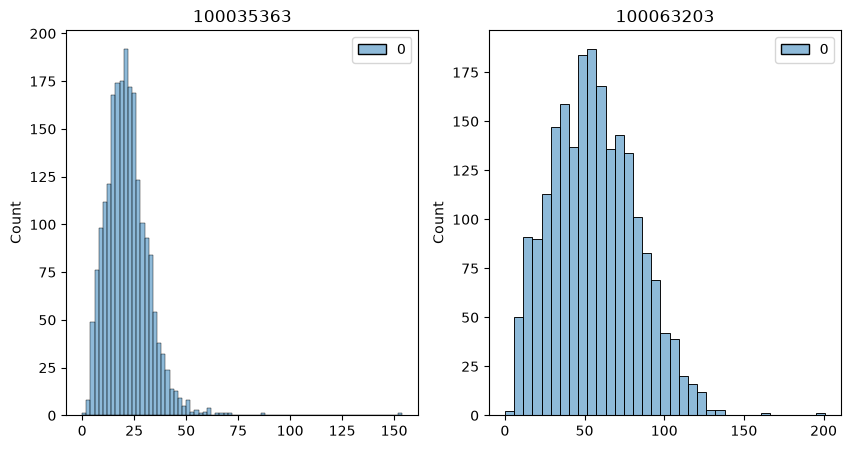

In [87]:
example_counters = [100035363, 100063203]
N = 2
fig, axs = plt.subplots(1, N, figsize=(5*N, 5))

for i in range(N):
    ax = axs[i]
    site_id = example_counters[i]
    station_channel_daily_peak = (
        counters
        .filter(pl.col("counter_site_id") == site_id)
        .group_by(by=pl.col("datetime").dt.date())
        .agg(pl.col("channels_all").max())
        .select(pl.col("channels_all"))
    )
    sns.histplot(station_channel_daily_peak, ax=ax)
    ax.set_title(site_id)

In [106]:
(
    counters
    .filter(pl.col("counter_site_id") == 100035363)
    .group_by(by=pl.col("datetime").dt.date())
    .agg(pl.col("channels_all").max())
    .filter(pl.col("channels_all") == 0)
)

by,channels_all
date,i64
2020-12-31,0


<Axes: ylabel='Count'>

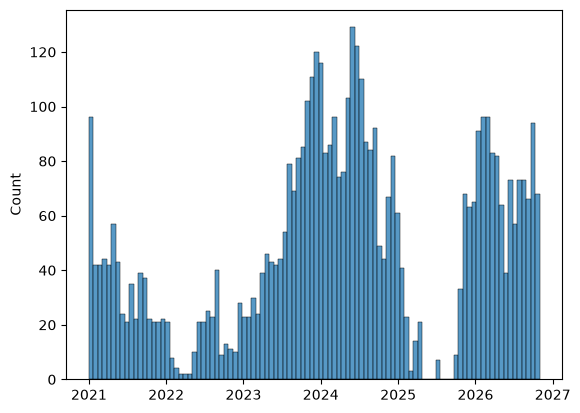

In [116]:
zero_days = (
    counters.group_by(
        pl.col("datetime").dt.date(),
        pl.col("counter_site_id"),
    )
    .agg(pl.col("channels_all").max())
    .filter(pl.col("channels_all") == 0)
)
sns.histplot(zero_days["datetime"], bins=100)